# AI Crop Doctor — M3 Fine-tuning with PlantVillage + PlantDoc

## 1. Imports, paths, and reproducibility

In [85]:
from pathlib import Path
import os, json, hashlib, re, unicodedata, warnings
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
INPUT_ROOT = Path('/kaggle/input')
OUTPUT_DIR = Path('/kaggle/working/AI_Crop_Doctor_M3_Finetuned')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Discover the attached files instead of assuming Kaggle dataset slugs.
def all_named(root, name):
    return [p for p in root.rglob(name) if p.exists()]

model_matches = all_named(INPUT_ROOT, 'mobilenetv3_best.keras')
split_matches = all_named(INPUT_ROOT, 'splits.csv')
map_matches = all_named(INPUT_ROOT, 'class_to_idx.json')
assert len(model_matches) == 1, f'Expected exactly one mobilenetv3_best.keras; found {model_matches}'
pairs = [(s, m) for s in split_matches for m in map_matches if s.parent == m.parent]
assert pairs, 'Could not find splits.csv and class_to_idx.json in the same preprocessing folder.'
MODEL_PATH = model_matches[0]
SPLITS_CSV, CLASS_MAP_JSON = pairs[0]
M1_DIR = SPLITS_CSV.parent

# PlantVillage root: folder containing color/, grayscale/, segmented/.
pv_roots = []
for color_dir in INPUT_ROOT.rglob('color'):
    if color_dir.is_dir() and (color_dir.parent / 'grayscale').is_dir() and (color_dir.parent / 'segmented').is_dir():
        pv_roots.append(color_dir.parent)
assert pv_roots, 'PlantVillage dataset not found. Attach the PlantVillage Dataset input.'
# Prefer the root whose path contains plantvillage.
pv_roots.sort(key=lambda p: ('plantvillage' not in str(p).lower(), len(str(p))))
PLANTVILLAGE_ROOT = pv_roots[0]
PLANTVILLAGE_COLOR_DIR = PLANTVILLAGE_ROOT / 'color'

# PlantDoc root: parent of train/ and test/ class folders.
pd_roots = []
for train_dir in INPUT_ROOT.rglob('train'):
    if train_dir.is_dir() and (train_dir.parent / 'test').is_dir() and 'plantdoc' in str(train_dir.parent).lower():
        pd_roots.append(train_dir.parent)
assert pd_roots, 'PlantDoc root with train/ and test/ folders not found.'
pd_roots.sort(key=lambda p: len(str(p)))
PLANTDOC_ROOT = pd_roots[0]
TRAIN_DIR, TEST_DIR = PLANTDOC_ROOT / 'train', PLANTDOC_ROOT / 'test'

for label, path in {'Model': MODEL_PATH, 'M1 splits': SPLITS_CSV, 'M1 class map': CLASS_MAP_JSON,
                    'PlantVillage color': PLANTVILLAGE_COLOR_DIR, 'PlantDoc train': TRAIN_DIR,
                    'PlantDoc test': TEST_DIR}.items():
    print(f'{label}: {path} | exists={path.exists()}')

print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

Model: /kaggle/input/models/omarwalied2005/ai-crop-doctor-mobilenetv3large/tensorflow2/default/1/mobilenetv3_best.keras | exists=True
M1 splits: /kaggle/input/datasets/omarwalied2005/preprocessing/Preprocessing/splits.csv | exists=True
M1 class map: /kaggle/input/datasets/omarwalied2005/preprocessing/Preprocessing/class_to_idx.json | exists=True
PlantVillage color: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color | exists=True
PlantDoc train: /kaggle/input/datasets/omarwalied2005/plantdoc/PlantDoc-Dataset/train | exists=True
PlantDoc test: /kaggle/input/datasets/omarwalied2005/plantdoc/PlantDoc-Dataset/test | exists=True
TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Load M1 class order, checkpoint, and split manifest

In [86]:
with open(CLASS_MAP_JSON, 'r', encoding='utf-8') as f:
    class_to_idx = json.load(f)
class_names = [name for name, idx in sorted(class_to_idx.items(), key=lambda x: int(x[1]))]
assert len(class_names) == 38, f'Expected 38 M1 classes, found {len(class_names)}'

# M1 manifest is used for label order and holdout duplicate hashes only.
# Its original New Plant Diseases image paths are not needed in this notebook.
m1 = pd.read_csv(SPLITS_CSV)
required = {'path', 'split', 'class', 'label', 'sha256'}
assert required.issubset(m1.columns), f'Missing M1 columns: {required - set(m1.columns)}'
m1['label'] = m1['label'].astype(int)
assert m1['label'].between(0, 37).all()
m1_hashes = set(m1['sha256'].dropna().astype(str))
m1_holdout_hashes = set(m1.loc[
    m1['split'].astype(str).str.lower().isin(['val', 'validation', 'test']), 'sha256'
].dropna().astype(str))
print('M1 manifest rows:', len(m1))
print('M1 classes:', len(class_names))
print('M1 validation/test hashes reserved from PlantVillage:', len(m1_holdout_hashes))

model = tf.keras.models.load_model(MODEL_PATH, compile=False)
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
assert tuple(model.input_shape[1:]) == (128, 128, 3)
assert int(model.output_shape[-1]) == len(class_names)
model.summary()

M1 manifest rows: 87867
M1 classes: 38
M1 validation/test hashes reserved from PlantVillage: 26317


Model: "MobileNetV3Large_M1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 4, 4, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │        36,518 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,032,870 (11.57 MB)

 Trainable params: 2,110,670 (8.05 MB)

 Non-trainable params: 922,200 (3.52 MB)

## 3. Inventory PlantDoc train/test folders

In [87]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def inventory_split(split_dir, split_name):
    rows = []
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        for p in class_dir.rglob("*"):
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
                rows.append({"path": str(p), "class": class_dir.name, "split": split_name})
    return pd.DataFrame(rows)

plantdoc_train = inventory_split(TRAIN_DIR, "train")
plantdoc_test = inventory_split(TEST_DIR, "test")
print("PlantDoc train:", len(plantdoc_train), "| classes:", plantdoc_train["class"].nunique())
print("PlantDoc test:", len(plantdoc_test), "| classes:", plantdoc_test["class"].nunique())
assert len(plantdoc_train) and len(plantdoc_test)

PlantDoc train: 2315 | classes: 28
PlantDoc test: 234 | classes: 27


## 4. Review PlantDoc-to-M1 class mapping

In [88]:
def norm_label(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode("ascii")
    s = s.lower().replace("&", " and ")
    s = re.sub(r"[^a-z0-9]+", " ", s)
    return " ".join(s.split())

MANUAL_CLASS_MAP = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "grape leaf black rot": "Grape___Black_rot",
}

# ---- Extended mappings (OPT-IN). Review each line; set the flag to False to use only the original 14. ----
USE_EXTENDED_MAPPING = True
CORE_FOLDERS = set(MANUAL_CLASS_MAP)          # the original 14 mapped folders (kept for a like-for-like comparison)
EXTENDED_CLASS_MAP = {
    "Apple leaf": "Apple___healthy",
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "Blueberry leaf": "Blueberry___healthy",
    "Cherry leaf": "Cherry_(including_sour)___healthy",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Peach leaf": "Peach___healthy",
    "Raspberry leaf": "Raspberry___healthy",
    "Soyabean leaf": "Soybean___healthy",
    "Strawberry leaf": "Strawberry___healthy",
    "Tomato leaf": "Tomato___healthy",
    "grape leaf": "Grape___healthy",
}
if USE_EXTENDED_MAPPING:
    for folder, target in EXTENDED_CLASS_MAP.items():
        if target in class_to_idx:
            MANUAL_CLASS_MAP[folder] = target
        else:
            print("Skipping extended mapping (target not in M1 classes):", folder, "->", target)

normalized_m1 = {norm_label(name): name for name in class_names}
plantdoc_classes = sorted(set(plantdoc_train["class"]) | set(plantdoc_test["class"]))
class_mapping = {}
for folder in plantdoc_classes:
    if folder in MANUAL_CLASS_MAP:
        target = MANUAL_CLASS_MAP[folder]
        if target not in class_to_idx:
            raise ValueError(f"Invalid M1 target for {folder}: {target}")
        class_mapping[folder] = target
    else:
        class_mapping[folder] = normalized_m1.get(norm_label(folder))

mapping_review = pd.DataFrame([
    {"plantdoc_folder": k, "mapped_m1_class": v,
     "status": "MAPPED" if v else "UNMAPPED"}
    for k, v in class_mapping.items()
])
display(mapping_review)
mapping_review.to_csv(OUTPUT_DIR / "plantdoc_class_mapping_review.csv", index=False)

,plantdoc_folder,mapped_m1_class,status
0,Apple Scab Leaf,Apple___Apple_scab,MAPPED
1,Apple leaf,Apple___healthy,MAPPED
2,Apple rust leaf,Apple___Cedar_apple_rust,MAPPED
3,Bell_pepper leaf,"Pepper,_bell___healthy",MAPPED
4,Bell_pepper leaf spot,"Pepper,_bell___Bacterial_spot",MAPPED
5,Blueberry leaf,Blueberry___healthy,MAPPED
6,Cherry leaf,Cherry_(including_sour)___healthy,MAPPED
7,Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,MAPPED
8,Corn leaf blight,Corn_(maize)___Northern_Leaf_Blight,MAPPED
9,Corn rust leaf,Corn_(maize)___Common_rust_,MAPPED


## 5. SHA-256 integrity audit and leakage-safe cohort construction

In [89]:
def sha256_file(path, chunk=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

def add_integrity(df, desc):
    hashes, readable = [], []
    for path in tqdm(df["path"], desc=desc):
        try:
            with Image.open(path) as im:
                im.verify()
            hashes.append(sha256_file(path))
            readable.append(True)
        except Exception:
            hashes.append(None)
            readable.append(False)
    out = df.copy()
    out["sha256"] = hashes
    out["readable"] = readable
    return out

plantdoc_train_audit = add_integrity(plantdoc_train, "Audit PlantDoc train")
plantdoc_test_audit = add_integrity(plantdoc_test, "Audit PlantDoc test")

m1_hashes = set(m1["sha256"].dropna().astype(str))
plantdoc_test_hashes = set(plantdoc_test_audit.loc[plantdoc_test_audit["readable"], "sha256"].dropna())
plantdoc_train_audit["m1_exact_match"] = plantdoc_train_audit["sha256"].isin(m1_hashes)
plantdoc_train_audit["plantdoc_test_exact_match"] = plantdoc_train_audit["sha256"].isin(plantdoc_test_hashes)

# Map labels
plantdoc_train_audit["m1_class"] = plantdoc_train_audit["class"].map(class_mapping)
plantdoc_train_audit["label"] = plantdoc_train_audit["m1_class"].map(class_to_idx)
plantdoc_test_audit["m1_class"] = plantdoc_test_audit["class"].map(class_mapping)
plantdoc_test_audit["label"] = plantdoc_test_audit["m1_class"].map(class_to_idx)

plantdoc_train_mapped = plantdoc_train_audit[
    plantdoc_train_audit["readable"] & plantdoc_train_audit["label"].notna()
].copy()
# Exclude exact duplicates of any M1 split and any PlantDoc test image from PlantDoc training.
plantdoc_train_clean = plantdoc_train_mapped[
    ~plantdoc_train_mapped["m1_exact_match"] &
    ~plantdoc_train_mapped["plantdoc_test_exact_match"]
].copy()

# Remove repeated exact hashes within the remaining PlantDoc training set.
plantdoc_train_clean = plantdoc_train_clean.drop_duplicates("sha256", keep="first").copy()
plantdoc_train_clean["label"] = plantdoc_train_clean["label"].astype(int)

# Keep a strict PlantDoc test cohort: mapped/readable, with no exact overlap against
# any M1 split or the retained training cohort.
plantdoc_test_mapped = plantdoc_test_audit[
    plantdoc_test_audit["readable"] & plantdoc_test_audit["label"].notna()
].copy()
plantdoc_test_mapped["exact_m1_match"] = plantdoc_test_mapped["sha256"].isin(m1_hashes)
retained_train_hashes = set(plantdoc_train_clean["sha256"].dropna())
plantdoc_test_mapped["exact_train_match"] = plantdoc_test_mapped["sha256"].isin(retained_train_hashes)
plantdoc_test_mapped = plantdoc_test_mapped[
    ~plantdoc_test_mapped["exact_m1_match"] & ~plantdoc_test_mapped["exact_train_match"]
].copy()
plantdoc_test_mapped["label"] = plantdoc_test_mapped["label"].astype(int)

print("PlantDoc train inventory:", len(plantdoc_train_audit))
print("PlantDoc train mapped/readable:", len(plantdoc_train_mapped))
print("PlantDoc train exact M1 duplicates:", int(plantdoc_train_audit["m1_exact_match"].sum()))
print("PlantDoc train exact PlantDoc-test overlaps:", int(plantdoc_train_audit["plantdoc_test_exact_match"].sum()))
print("PlantDoc train retained for fine-tuning:", len(plantdoc_train_clean))
print("PlantDoc test mapped/readable, held out:", len(plantdoc_test_mapped))
print("Train classes:", plantdoc_train_clean["label"].nunique(), "| Test classes:", plantdoc_test_mapped["label"].nunique())

plantdoc_train_audit.to_csv(OUTPUT_DIR / "plantdoc_train_integrity_audit.csv", index=False)
plantdoc_test_audit.to_csv(OUTPUT_DIR / "plantdoc_test_integrity_audit.csv", index=False)
plantdoc_train_clean.to_csv(OUTPUT_DIR / "plantdoc_train_deduplicated_manifest.csv", index=False)
plantdoc_test_mapped.to_csv(OUTPUT_DIR / "plantdoc_test_mapped_manifest.csv", index=False)

assert len(plantdoc_train_clean) > 0, "No PlantDoc train images remain after mapping/deduplication."
assert len(plantdoc_test_mapped) > 0, "No mapped PlantDoc test images available."

Audit PlantDoc train:   0%|          | 0/2315 [00:00<?, ?it/s]

Audit PlantDoc test:   0%|          | 0/234 [00:00<?, ?it/s]

PlantDoc train inventory: 2315
PlantDoc train mapped/readable: 2313
PlantDoc train exact M1 duplicates: 0
PlantDoc train exact PlantDoc-test overlaps: 11
PlantDoc train retained for fine-tuning: 2301
PlantDoc test mapped/readable, held out: 234
Train classes: 27 | Test classes: 27


## 5b. Build the PlantVillage manifest directly from the attached `color/` folder

In [90]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

pv_rows = []
for class_dir in sorted(p for p in PLANTVILLAGE_COLOR_DIR.iterdir() if p.is_dir()):
    if class_dir.name not in class_to_idx:
        print('Skipping unknown PlantVillage class folder:', class_dir.name)
        continue
    label = int(class_to_idx[class_dir.name])
    for image_path in class_dir.rglob('*'):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTS:
            pv_rows.append({'path': str(image_path), 'class': class_dir.name, 'label': label})

plantvillage_raw = pd.DataFrame(pv_rows)
assert len(plantvillage_raw), f'No images found under {PLANTVILLAGE_COLOR_DIR}'
print('PlantVillage color images discovered:', len(plantvillage_raw))
print('PlantVillage folders mapped:', plantvillage_raw['class'].nunique(), '/ 38')
print('Missing class folders:', sorted(set(class_names) - set(plantvillage_raw['class'].unique())))
display(plantvillage_raw.groupby('class').size().rename('images').to_frame())

PlantVillage color images discovered: 54305
PlantVillage folders mapped: 38 / 38
Missing class folders: []


,images
class,
Apple___Apple_scab,630
Apple___Black_rot,621
Apple___Cedar_apple_rust,275
Apple___healthy,1645
Blueberry___healthy,1502
Cherry_(including_sour)___Powdery_mildew,1052
Cherry_(including_sour)___healthy,854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,513
Corn_(maize)___Common_rust_,1192


In [91]:
def sha256_file(path, chunk=1024 * 1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(chunk), b''):
            h.update(block)
    return h.hexdigest()

def add_integrity(df, desc):
    hashes, readable = [], []
    for path in tqdm(df['path'], desc=desc):
        try:
            with Image.open(path) as im:
                im.verify()
            hashes.append(sha256_file(path))
            readable.append(True)
        except Exception:
            hashes.append(None)
            readable.append(False)
    out = df.copy()
    out['sha256'] = hashes
    out['readable'] = readable
    return out

# Hash PlantVillage color files once. Exclude exact M1 validation/test overlap,
# then deduplicate repeated exact files within PlantVillage.
plantvillage_audit = add_integrity(plantvillage_raw, 'Audit PlantVillage color')
plantvillage_audit['m1_holdout_match'] = plantvillage_audit['sha256'].isin(m1_holdout_hashes)
plantvillage_audit['m1_train_match'] = (
    plantvillage_audit['sha256'].isin(m1_hashes - m1_holdout_hashes)
)
plantvillage_clean = plantvillage_audit[
    plantvillage_audit['readable'] & ~plantvillage_audit['m1_holdout_match']
].copy()
plantvillage_clean = plantvillage_clean.drop_duplicates('sha256', keep='first').reset_index(drop=True)
plantvillage_clean['label'] = plantvillage_clean['label'].astype(int)

print('PlantVillage inventory:', len(plantvillage_audit))
print('Unreadable:', int((~plantvillage_audit['readable']).sum()))
print('Exact M1 validation/test overlaps excluded:', int(plantvillage_audit['m1_holdout_match'].sum()))
print('PlantVillage images retained:', len(plantvillage_clean))
print('PlantVillage class coverage:', plantvillage_clean['label'].nunique(), '/ 38')
print('PlantVillage exact matches with M1 train (allowed reuse):', int(plantvillage_audit['m1_train_match'].sum()))
assert plantvillage_clean['label'].nunique() == 38, 'PlantVillage training source does not cover all 38 classes.'
plantvillage_audit.to_csv(OUTPUT_DIR / 'plantvillage_integrity_audit.csv', index=False)
plantvillage_clean.to_csv(OUTPUT_DIR / 'plantvillage_clean_manifest.csv', index=False)

Audit PlantVillage color:   0%|          | 0/54305 [00:00<?, ?it/s]

PlantVillage inventory: 54305
Unreadable: 0
Exact M1 validation/test overlaps excluded: 13684
PlantVillage images retained: 40608
PlantVillage class coverage: 38 / 38
PlantVillage exact matches with M1 train (allowed reuse): 32156


## 6. Create leakage-aware training and validation manifests

In [92]:
from sklearn.model_selection import train_test_split

# Split PlantVillage by class to create an independent validation subset.
pv_train_parts, pv_val_parts = [], []
for label, group in plantvillage_clean.groupby('label'):
    if len(group) < 2:
        raise ValueError(f'PlantVillage class {class_names[int(label)]} has fewer than 2 images.')
    g_train, g_val = train_test_split(group, test_size=0.15, random_state=SEED)
    pv_train_parts.append(g_train)
    pv_val_parts.append(g_val)
pv_train_df = pd.concat(pv_train_parts, ignore_index=True)
pv_val_df = pd.concat(pv_val_parts, ignore_index=True)

# Split mapped PlantDoc training images into train/validation, never using PlantDoc test.
pd_all = plantdoc_train_clean[['path', 'label']].reset_index(drop=True)
pd_train_parts, pd_val_parts = [], []
for label, group in pd_all.groupby('label'):
    if len(group) >= 2:
        g_train, g_val = train_test_split(group, test_size=0.15, random_state=SEED)
        pd_train_parts.append(g_train)
        pd_val_parts.append(g_val)
    else:
        # A singleton is retained for training, not validation.
        pd_train_parts.append(group)
pd_train = pd.concat(pd_train_parts, ignore_index=True) if pd_train_parts else pd.DataFrame(columns=['path','label'])
pd_val = pd.concat(pd_val_parts, ignore_index=True) if pd_val_parts else pd.DataFrame(columns=['path','label'])

train_df = pd.concat([
    pv_train_df[['path', 'label']].assign(source='PlantVillage'),
    pd_train[['path', 'label']].assign(source='PlantDoc'),
], ignore_index=True)
val_df = pd.concat([
    pv_val_df[['path', 'label']].assign(source='PlantVillage_validation'),
    pd_val[['path', 'label']].assign(source='PlantDoc_validation'),
], ignore_index=True)

train_df['label'] = train_df['label'].astype(int)
val_df['label'] = val_df['label'].astype(int)

print('Combined training images:', len(train_df))
display(train_df.groupby('source').size().rename('images').to_frame())
print('\nValidation images:')
display(val_df.groupby('source').size().rename('images').to_frame())
train_classes = set(train_df['label'].unique())
val_classes = set(val_df['label'].unique())
missing_train = [class_names[i] for i in range(38) if i not in train_classes]
missing_val = [class_names[i] for i in range(38) if i not in val_classes]
print('Training class coverage:', len(train_classes), '/ 38')
print('Validation class coverage:', len(val_classes), '/ 38')
if missing_train:
    raise ValueError(f'Training is missing classes: {missing_train}')
if missing_val:
    print('Note: validation has no examples for:', missing_val)
assert train_df['label'].between(0, 37).all() and val_df['label'].between(0, 37).all()
assert (train_df['source'] == 'PlantVillage').sum() > 0
assert (train_df['source'] == 'PlantDoc').sum() > 0

train_df.to_csv(OUTPUT_DIR / 'combined_training_manifest.csv', index=False)
val_df.to_csv(OUTPUT_DIR / 'validation_manifest.csv', index=False)
pv_val_df.to_csv(OUTPUT_DIR / 'plantvillage_validation_manifest.csv', index=False)

Combined training images: 36442


,images
source,
PlantDoc,1942
PlantVillage,34500



Validation images:


,images
source,
PlantDoc_validation,359
PlantVillage_validation,6108


Training class coverage: 38 / 38
Validation class coverage: 38 / 38


## 7. Build efficient `tf.data` pipelines

In [93]:
AUTOTUNE = tf.data.AUTOTUNE

def decode_resize(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, method='bilinear')
    image = tf.cast(image, tf.float32)  # 0..255; model has internal rescaling
    return image, tf.cast(label, tf.int32)

L = tf.keras.layers
def build_augment(strong):
    """PlantVillage = studio photos -> moderate colour/zoom/shift so the model stops relying on
    clean backgrounds. PlantDoc = in-the-wild -> strong geometric/colour jitter + random erasing."""
    layers = [
        L.RandomFlip('horizontal_and_vertical' if strong else 'horizontal'),
        L.RandomRotation(0.15 if strong else 0.10),
        L.RandomZoom(0.30 if strong else 0.20),
        L.RandomTranslation(0.10 if strong else 0.05, 0.10 if strong else 0.05),
        L.RandomColorJitter(value_range=(0, 255),
                            brightness_factor=0.25 if strong else 0.15,
                            contrast_factor=0.25 if strong else 0.15,
                            saturation_factor=0.30 if strong else 0.20,
                            hue_factor=0.05 if strong else 0.03),
    ]
    if strong:
        layers.append(L.RandomErasing(factor=0.3, scale=(0.02, 0.15), value_range=(0, 255)))
    return tf.keras.Sequential(layers, name='aug_strong' if strong else 'aug_moderate')

augment_pv, augment_pd = build_augment(False), build_augment(True)

def make_dataset(df, training=False, aug=None):
    """Unbatched dataset."""
    ds = tf.data.Dataset.from_tensor_slices((
        df['path'].astype(str).to_numpy(),
        df['label'].astype(np.int32).to_numpy()
    ))
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    if training and aug is not None:
        ds = ds.map(lambda x, y: (tf.clip_by_value(aug(x, training=True), 0.0, 255.0), y),
                    num_parallel_calls=AUTOTUNE)
    return ds

# Sample PlantDoc more often than its raw share to encourage domain adaptation.
PD_FRACTION = 0.25
STEPS_PER_EPOCH = max(1, int(np.ceil(len(train_df) / BATCH_SIZE)))
pv_ds = make_dataset(train_df[train_df['source'] == 'PlantVillage'], True, augment_pv).repeat()
pd_ds = make_dataset(train_df[train_df['source'] == 'PlantDoc'], True, augment_pd).repeat()
train_ds = (tf.data.Dataset.sample_from_datasets(
    [pv_ds, pd_ds], weights=[1 - PD_FRACTION, PD_FRACTION], seed=SEED
).batch(BATCH_SIZE).prefetch(AUTOTUNE))

# Two validation sets: PlantVillage (large) and PlantDoc (small, in-the-wild).
assert len(pd_val) > 0, 'Need a PlantDoc validation split for checkpoint selection.'
val_ds = make_dataset(pv_val_df, False).batch(BATCH_SIZE).prefetch(AUTOTUNE)
pd_val_ds = make_dataset(pd_val, False).batch(BATCH_SIZE).prefetch(AUTOTUNE)

class BalancedValidation(tf.keras.callbacks.Callback):
    """Adds val_pd_accuracy / val_balanced = mean(PlantVillage-val acc, PlantDoc-val acc) to the logs.
    Put it BEFORE ModelCheckpoint / EarlyStopping / ReduceLROnPlateau so they can monitor it.
    (A plain pooled validation is ~97% PlantVillage and would reward forgetting PlantDoc.)"""
    def __init__(self, pd_val_dataset):
        super().__init__(); self.pd_val_dataset = pd_val_dataset
    def on_epoch_end(self, epoch, logs=None):
        res = self.model.evaluate(self.pd_val_dataset, verbose=0, return_dict=True)
        logs['val_pd_accuracy'] = float(res['accuracy'])
        logs['val_pd_loss'] = float(res['loss'])
        logs['val_balanced'] = 0.5 * (logs['val_accuracy'] + logs['val_pd_accuracy'])
        print(f" - val_pd_accuracy: {logs['val_pd_accuracy']:.4f} - val_balanced: {logs['val_balanced']:.4f}")

print('train steps/epoch:', STEPS_PER_EPOCH, '| PV val batches:', len(val_ds), '| PD val images:', len(pd_val))


train steps/epoch: 1139 | PV val batches: 191 | PD val images: 359


## 8. Fine-tune stage 1 — train the classification head

In [94]:
# Identify nested feature extractor
nested_models = [layer for layer in model.layers if isinstance(layer, tf.keras.Model)]
assert nested_models, "Could not identify nested MobileNet backbone; inspect model.summary()."
backbone = nested_models[0]
backbone.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

HEAD_EPOCHS = 4
head_history = model.fit(
    train_ds,
    validation_data=val_ds,
    steps_per_epoch=STEPS_PER_EPOCH,
    epochs=HEAD_EPOCHS,
    callbacks=[
        BalancedValidation(pd_val_ds),   # must come first
        tf.keras.callbacks.ModelCheckpoint(
            OUTPUT_DIR / "stage1_best.keras",
            monitor="val_balanced", mode="max", save_best_only=True
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_balanced", mode="max", patience=2, restore_best_weights=True
        ),
        tf.keras.callbacks.CSVLogger(OUTPUT_DIR / "stage1_training_log.csv")
    ]
)


Epoch 1/4
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.4600 - loss: 2.3872

E0000 00:00:1793910244.106903     142 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793910244.284897     142 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


 - val_pd_accuracy: 0.2312 - val_balanced: 0.5955
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 228s 191ms/step - accuracy: 0.5147 - loss: 2.0792 - val_accuracy: 0.9597 - val_loss: 0.1486 - val_pd_accuracy: 0.2312 - val_pd_loss: 3.2532 - val_balanced: 0.5955
Epoch 2/4
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.5914 - loss: 1.6534 - val_pd_accuracy: 0.2507 - val_balanced: 0.6048
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 205s 180ms/step - accuracy: 0.6004 - loss: 1.5911 - val_accuracy: 0.9589 - val_loss: 0.1522 - val_pd_accuracy: 0.2507 - val_pd_loss: 2.9615 - val_balanced: 0.6048
Epoch 3/4
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.6239 - loss: 1.4460 - val_pd_accuracy: 0.2813 - val_balanced: 0.6188
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 204s 179ms/step - accuracy: 0.6314 - loss: 1.4061 - val_accuracy: 0.9563 - val_loss: 0.1559 - val_pd_accuracy: 0.2813 - val_pd_loss: 2.7786 - val_balanced: 0.6188
Epoch 4/4
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.6480 - loss: 1.3184 - v

## 9. Fine-tune stage 2 — unfreeze upper backbone layers

In [95]:
# Continue from the best stage-1 checkpoint if it exists.
stage1_path = OUTPUT_DIR / "stage1_best.keras"
if stage1_path.exists():
    model = tf.keras.models.load_model(stage1_path, compile=False)
    nested_models = [layer for layer in model.layers if isinstance(layer, tf.keras.Model)]
    backbone = nested_models[0]

backbone.trainable = True
UNFREEZE_LAST_N = 60
for layer in backbone.layers[:-UNFREEZE_LAST_N]:
    layer.trainable = False
for layer in backbone.layers[-UNFREEZE_LAST_N:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

FINE_TUNE_LR = 2e-5
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=FINE_TUNE_LR),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

FINE_TUNE_EPOCHS = 12
fine_history = model.fit(
    train_ds,
    validation_data=val_ds,
    steps_per_epoch=STEPS_PER_EPOCH,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=[
        BalancedValidation(pd_val_ds),   # must come first
        tf.keras.callbacks.ModelCheckpoint(
            OUTPUT_DIR / "mobilenetv3_plantvillage_plantdoc_best.keras",
            monitor="val_balanced", mode="max", save_best_only=True
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_balanced", mode="max", patience=4, restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_balanced", mode="max", factor=0.3, patience=2, min_lr=1e-7
        ),
        tf.keras.callbacks.CSVLogger(OUTPUT_DIR / "stage2_training_log.csv")
    ]
)


Epoch 1/12
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.6954 - loss: 1.0873 - val_pd_accuracy: 0.3231 - val_balanced: 0.6264
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 235s 192ms/step - accuracy: 0.7127 - loss: 0.9962 - val_accuracy: 0.9296 - val_loss: 0.2159 - val_pd_accuracy: 0.3231 - val_pd_loss: 2.4127 - val_balanced: 0.6264 - learning_rate: 2.0000e-05
Epoch 2/12
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.7491 - loss: 0.8362 - val_pd_accuracy: 0.3621 - val_balanced: 0.6478
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 207s 182ms/step - accuracy: 0.7546 - loss: 0.8135 - val_accuracy: 0.9335 - val_loss: 0.2019 - val_pd_accuracy: 0.3621 - val_pd_loss: 2.2805 - val_balanced: 0.6478 - learning_rate: 2.0000e-05
Epoch 3/12
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.7680 - loss: 0.7561 - val_pd_accuracy: 0.3621 - val_balanced: 0.6489
1139/1139 ━━━━━━━━━━━━━━━━━━━━ 207s 182ms/step - accuracy: 0.7731 - loss: 0.7340 - val_accuracy: 0.9357 - val_loss: 0.1936 - val_pd_accurac

## 10. Load best checkpoint and evaluate untouched PlantDoc test

PlantDoc test, all mapped classes (n=234):
  no TTA : acc 0.4444 | macro-F1 0.4180
  with TTA: acc 0.4487 | macro-F1 0.4236
Original 14-class subset (n=114), comparable with earlier runs:
  no TTA : acc 0.3509 | with TTA: acc 0.3596
95% binomial margin on this test set is about +/- 3.2 points
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.50      0.30      0.38        10
                          Apple___Cedar_apple_rust       0.24      0.70      0.36        10
                                   Apple___healthy       0.86      0.67      0.75         9
                               Blueberry___healthy       0.36      0.45      0.40        11
                 Cherry_(including_sour)___healthy       0.31      0.40      0.35        10
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.00      0.00      0.00         3
                       Corn_(maize)___Common_rust_       0.73

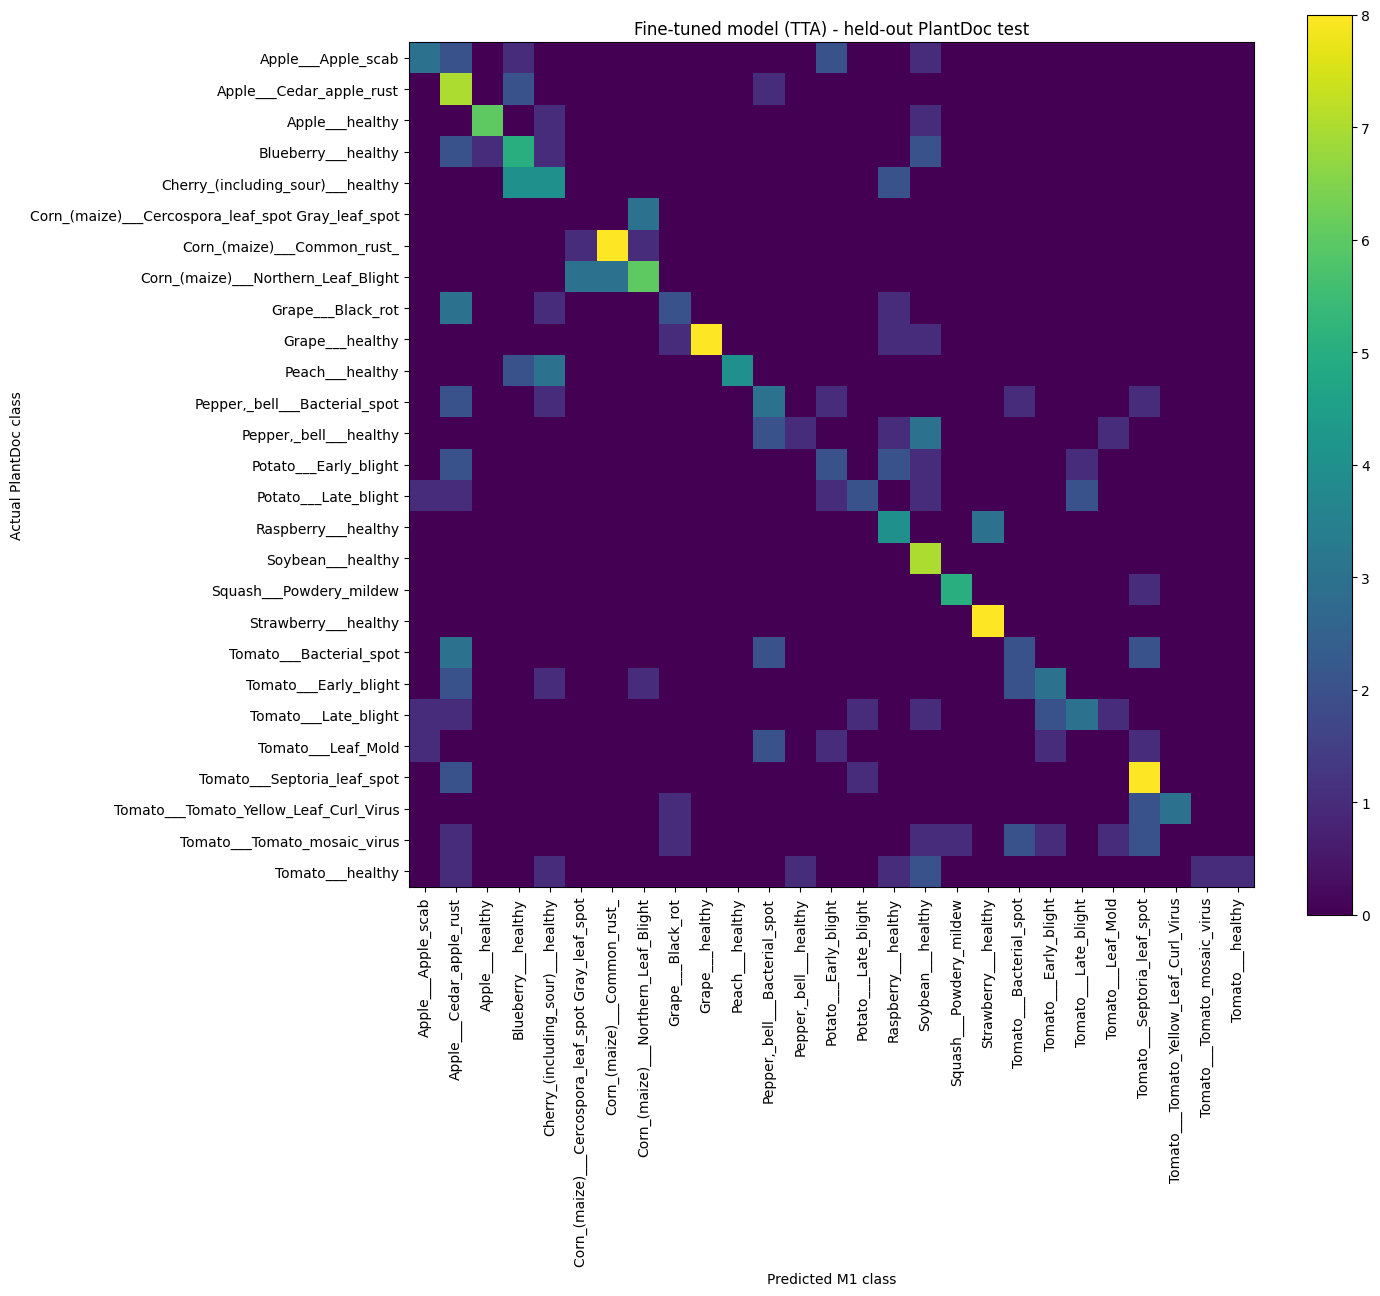

{'accuracy': 0.44871794871794873, 'accuracy_no_tta': 0.4444444444444444, 'macro_f1_present_classes': 0.4235549373061757, 'core14_accuracy': 0.35964912280701755, 'n_test_images': 234, 'n_core14_images': 114, 'n_present_classes': 27}


In [96]:
BEST_MODEL_PATH = OUTPUT_DIR / "mobilenetv3_plantvillage_plantdoc_best.keras"
assert BEST_MODEL_PATH.exists(), "Best fine-tuned checkpoint was not saved."
finetuned_model = tf.keras.models.load_model(BEST_MODEL_PATH, compile=False)

def predict_probs(mdl, df, tta=False):
    """Softmax probabilities. tta=True averages 4 fixed views (orig, h-flip, v-flip, 85% centre crop).
    TTA is decided in advance (not tuned on the test set); it costs ~4x inference time."""
    ds = (tf.data.Dataset.from_tensor_slices((df["path"].astype(str).to_numpy(),
                                              df["label"].astype(np.int32).to_numpy()))
          .map(decode_resize, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE))
    views = [lambda x: x]
    if tta:
        views += [lambda x: tf.image.flip_left_right(x),
                  lambda x: tf.image.flip_up_down(x),
                  lambda x: tf.image.resize(tf.image.central_crop(x, 0.85), IMG_SIZE, method="bilinear")]
    out = []
    for x, _ in ds:
        p = tf.add_n([mdl(v(x), training=False) for v in views]) / float(len(views))
        out.append(p.numpy())
    return np.concatenate(out, axis=0)

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
y_test = plantdoc_test_mapped["label"].to_numpy(dtype=np.int32)
core_mask = plantdoc_test_mapped["class"].isin(CORE_FOLDERS).to_numpy()
present = np.unique(y_test)
target_names = [class_names[int(i)] for i in present]

probs_plain = predict_probs(finetuned_model, plantdoc_test_mapped, tta=False)
probs_tta = predict_probs(finetuned_model, plantdoc_test_mapped, tta=True)
pred_plain, pred_test = probs_plain.argmax(1), probs_tta.argmax(1)   # final model output = TTA

print("PlantDoc test, all mapped classes (n=%d):" % len(y_test))
print("  no TTA : acc %.4f | macro-F1 %.4f" % (accuracy_score(y_test, pred_plain),
      f1_score(y_test, pred_plain, labels=present, average="macro", zero_division=0)))
print("  with TTA: acc %.4f | macro-F1 %.4f" % (accuracy_score(y_test, pred_test),
      f1_score(y_test, pred_test, labels=present, average="macro", zero_division=0)))
print("Original 14-class subset (n=%d), comparable with earlier runs:" % core_mask.sum())
print("  no TTA : acc %.4f | with TTA: acc %.4f" % (accuracy_score(y_test[core_mask], pred_plain[core_mask]),
      accuracy_score(y_test[core_mask], pred_test[core_mask])))
n = len(y_test)
print("95%% binomial margin on this test set is about +/- %.1f points" % (196 * np.sqrt(0.25 / n) / 2))
print(classification_report(y_test, pred_test, labels=present, target_names=target_names, zero_division=0))

report = classification_report(y_test, pred_test, labels=present, target_names=target_names,
                               output_dict=True, zero_division=0)
pd.DataFrame(report).transpose().to_csv(OUTPUT_DIR / "finetuned_plantdoc_test_classification_report.csv")

cm = confusion_matrix(y_test, pred_test, labels=present)
plt.figure(figsize=(max(9, len(present)*0.55), max(7, len(present)*0.48)))
plt.imshow(cm, interpolation="nearest")
plt.xticks(range(len(target_names)), target_names, rotation=90)
plt.yticks(range(len(target_names)), target_names)
plt.xlabel("Predicted M1 class")
plt.ylabel("Actual PlantDoc class")
plt.title("Fine-tuned model (TTA) - held-out PlantDoc test")
plt.colorbar()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "finetuned_plantdoc_test_confusion_matrix.png", dpi=180)
plt.show()

metrics = {
    "accuracy": float(accuracy_score(y_test, pred_test)),
    "accuracy_no_tta": float(accuracy_score(y_test, pred_plain)),
    "macro_f1_present_classes": float(f1_score(y_test, pred_test, labels=present, average="macro", zero_division=0)),
    "core14_accuracy": float(accuracy_score(y_test[core_mask], pred_test[core_mask])),
    "n_test_images": int(len(y_test)),
    "n_core14_images": int(core_mask.sum()),
    "n_present_classes": int(len(present))
}
print(metrics)


## 11. Compare original M2 checkpoint vs fine-tuned checkpoint on the same held-out PlantDoc test

In [97]:
baseline_model = tf.keras.models.load_model(MODEL_PATH, compile=False)
baseline_pred = predict_probs(baseline_model, plantdoc_test_mapped, tta=False).argmax(1)

def row(name, pred):
    return {"model": name,
            "accuracy_all_mapped": float(accuracy_score(y_test, pred)),
            "macro_f1_all_mapped": float(f1_score(y_test, pred, labels=present, average="macro", zero_division=0)),
            "accuracy_core14": float(accuracy_score(y_test[core_mask], pred[core_mask]))}

comparison = pd.DataFrame([
    row("Original M2 MobileNetV3Large", baseline_pred),
    row("Fine-tuned (no TTA)", pred_plain),
    row("Fine-tuned (+TTA)", pred_test),
])
display(comparison)
comparison.to_csv(OUTPUT_DIR / "baseline_vs_finetuned_plantdoc_test.csv", index=False)


,model,accuracy_all_mapped,macro_f1_all_mapped,accuracy_core14
0,Original M2 MobileNetV3Large,0.162393,0.146824,0.140351
1,Fine-tuned (no TTA),0.444444,0.418021,0.350877
2,Fine-tuned (+TTA),0.448718,0.423555,0.359649


## 11b. Forgetting check — held-out PlantVillage validation subset

In [98]:
full_pv_val_ds = make_dataset(pv_val_df, training=False).batch(BATCH_SIZE).prefetch(AUTOTUNE)
y_pv = pv_val_df['label'].to_numpy(dtype=np.int32)
rows = []
for name, mdl in [('Original M2', baseline_model), ('Fine-tuned', finetuned_model)]:
    p = mdl.predict(full_pv_val_ds, verbose=0).argmax(axis=1)
    rows.append({'model': name, 'plantvillage_val_acc': accuracy_score(y_pv, p), 'n': len(y_pv)})
display(pd.DataFrame(rows))

,model,plantvillage_val_acc,n
0,Original M2,0.992633,6108
1,Fine-tuned,0.945481,6108


## 12. Save run metadata and artifacts

In [99]:
summary = {
    'milestone': 'M3 fine-tuning experiment',
    'base_checkpoint': str(MODEL_PATH),
    'fine_tuned_checkpoint': str(BEST_MODEL_PATH),
    'training_sources': {
        'plantvillage_color_images_retained': int(len(plantvillage_clean)),
        'plantvillage_train_images': int(len(pv_train_df)),
        'plantdoc_train_mapped_readable_before_dedup': int(len(plantdoc_train_mapped)),
        'plantdoc_train_retained_after_exact_dedup': int(len(plantdoc_train_clean)),
        'plantdoc_train_images_used': int(len(pd_train)),
        'combined_training_images': int(len(train_df))
    },
    'validation': {
        'source': 'stratified PlantVillage validation + held-out split of mapped PlantDoc train',
        'images': int(len(val_df)),
        'plantvillage_validation_images': int(len(pv_val_df)),
        'plantdoc_validation_images': int(len(pd_val))
    },
    'sampling': {'plantdoc_fraction_per_batch': PD_FRACTION, 'steps_per_epoch': STEPS_PER_EPOCH},
    'v3_settings': {'extended_mapping': USE_EXTENDED_MAPPING, 'core_folders': sorted(CORE_FOLDERS), 'tta_views': 4, 'checkpoint_metric': 'val_balanced'},
    'held_out_plantdoc_test': {
        'images': int(len(plantdoc_test_mapped)),
        'classes': int(plantdoc_test_mapped['label'].nunique()),
        'metrics': metrics
    },
    'baseline_vs_finetuned': comparison.to_dict(orient='records'),
    'class_mapping': class_mapping,
    'notes': [
        'PlantDoc test was not used for training or checkpoint selection.',
        'PlantVillage images matching M1 validation/test hashes were excluded.',
        'M1 training images were not required because the original M1 dataset image directory was not attached.',
        'PlantDoc training images with exact hash overlap against any M1 split or PlantDoc test were excluded.',
        'Only reviewed PlantDoc-to-M1 class mappings were included.',
        'Exact hashes do not detect perceptual near-duplicates.'
    ]
}
with open(OUTPUT_DIR / 'm3_finetuning_summary.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, indent=2)
print('Saved artifacts to:', OUTPUT_DIR)
print('\n'.join(sorted(p.name for p in OUTPUT_DIR.iterdir())))

Saved artifacts to: /kaggle/working/AI_Crop_Doctor_M3_Finetuned
baseline_vs_finetuned_plantdoc_test.csv
combined_training_manifest.csv
finetuned_plantdoc_test_classification_report.csv
finetuned_plantdoc_test_confusion_matrix.png
m1_validation_manifest.csv
m3_finetuning_summary.json
mobilenetv3_plantvillage_plantdoc_best.keras
plantdoc_class_mapping_review.csv
plantdoc_test_integrity_audit.csv
plantdoc_test_mapped_manifest.csv
plantdoc_train_deduplicated_manifest.csv
plantdoc_train_integrity_audit.csv
plantvillage_clean_manifest.csv
plantvillage_color_deduplicated_manifest.csv
plantvillage_integrity_audit.csv
plantvillage_validation_manifest.csv
stage1_best.keras
stage1_training_log.csv
stage2_training_log.csv
validation_manifest.csv


## 13. Robustness testing

In [100]:

from sklearn.metrics import accuracy_score, f1_score
import time

def transform_batch(x, mode):
    x = tf.cast(x, tf.float32)
    if mode == "original":
        return x
    if mode == "corner_mask":
        h, w = tf.shape(x)[1], tf.shape(x)[2]
        yy, xx = tf.range(h)[:, None], tf.range(w)[None, :]
        corners = ((yy < h//4) | (yy >= 3*h//4)) & ((xx < w//4) | (xx >= 3*w//4))
        return x * tf.cast(~corners, x.dtype)[None, ..., None]
    if mode == "centre_crop":
        return tf.image.resize(tf.image.central_crop(x, 0.75), IMG_SIZE)
    if mode == "brightness":
        return tf.clip_by_value(tf.image.adjust_brightness(x, 0.15), 0., 255.)
    if mode == "contrast":
        return tf.clip_by_value(tf.image.adjust_contrast(x, 1.35), 0., 255.)
    raise ValueError(mode)

def predict_robustness(mdl, df, mode):
    ds = tf.data.Dataset.from_tensor_slices(
        (df.path.astype(str).to_numpy(), df.label.astype(np.int32).to_numpy())
    ).map(decode_resize, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)
    outputs = []
    for x, _ in ds:
        outputs.append(mdl(transform_batch(x, mode), training=False).numpy())
    return np.concatenate(outputs)

robustness_rows = []
for condition in ["original", "corner_mask", "centre_crop", "brightness", "contrast"]:
    pred = predict_robustness(finetuned_model, plantdoc_test_mapped, condition).argmax(1)
    robustness_rows.append({
        "condition": condition, "accuracy": accuracy_score(y_test, pred),
        "macro_f1": f1_score(y_test, pred, labels=present, average="macro", zero_division=0),
        "n": len(y_test)
    })
robustness_report = pd.DataFrame(robustness_rows)
display(robustness_report)
robustness_report.to_csv(OUTPUT_DIR / "m3_robustness_report.csv", index=False)


,condition,accuracy,macro_f1,n
0,original,0.444444,0.418021,234
1,corner_mask,0.384615,0.355869,234
2,centre_crop,0.431624,0.394026,234
3,brightness,0.444444,0.418021,234
4,contrast,0.444444,0.419320,234


## 14. Grad-CAM explainability

Backbone: MobileNetV3Large
Last convolutional layer: conv_1


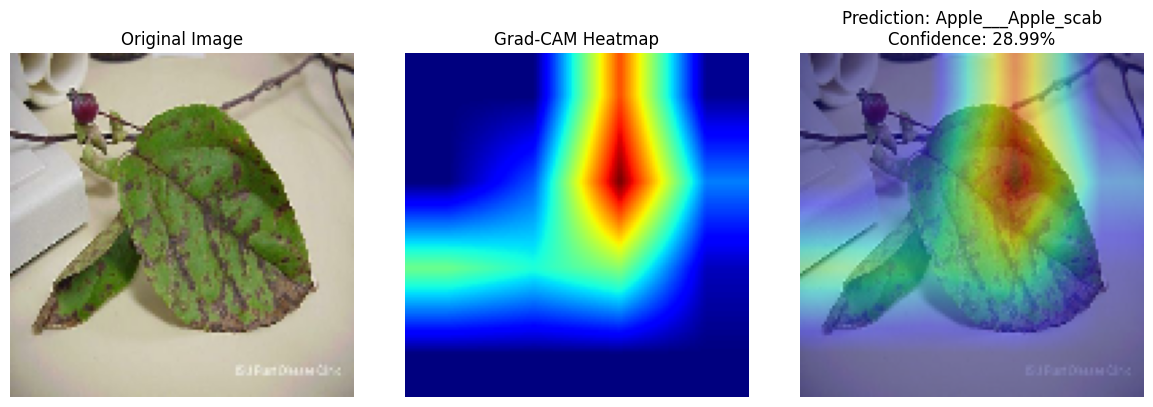

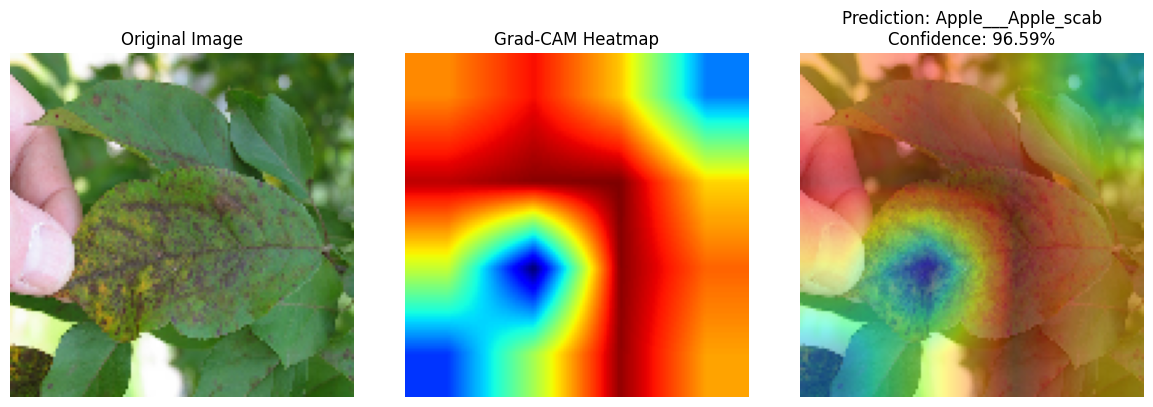

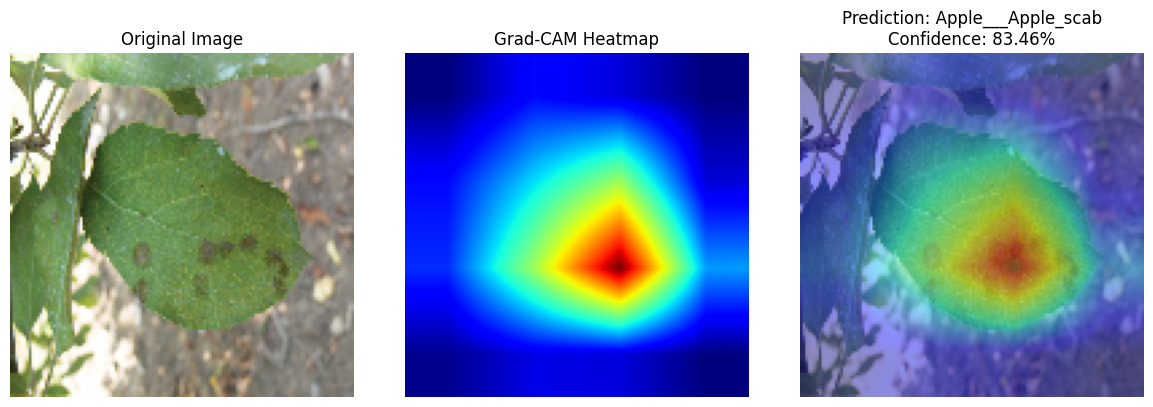

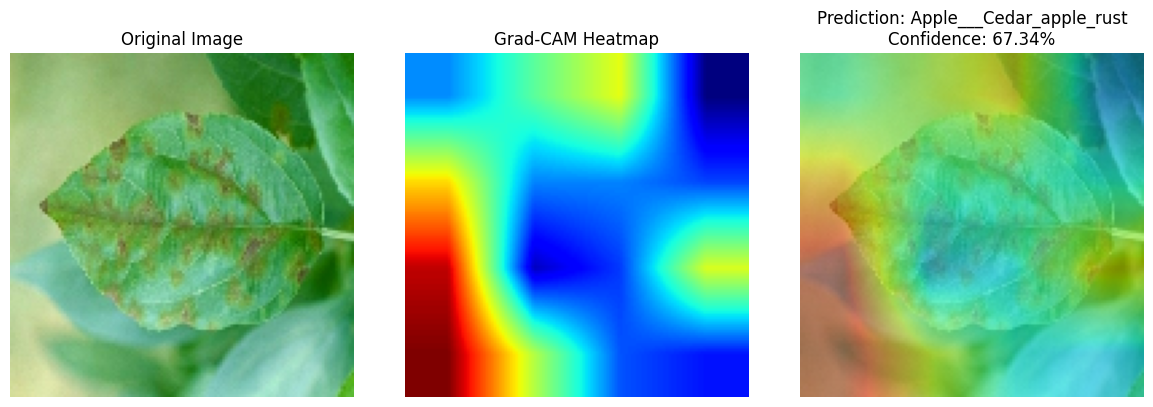

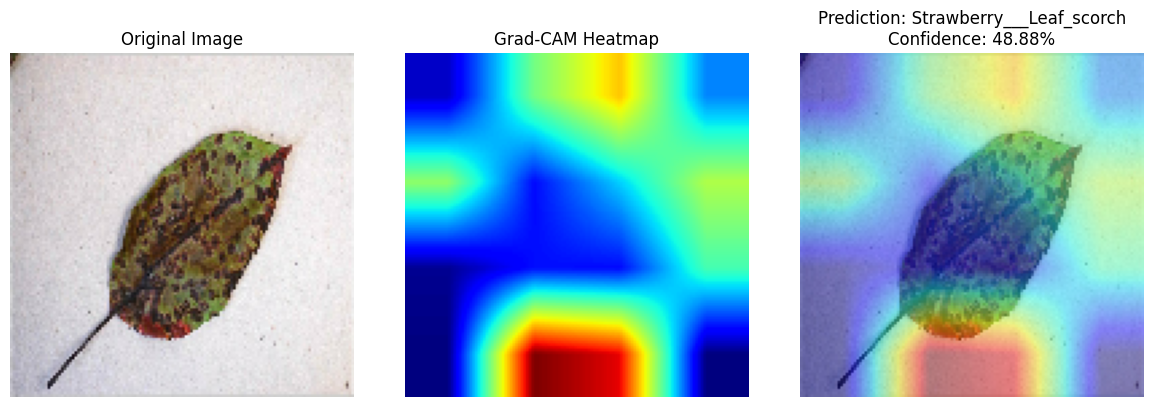

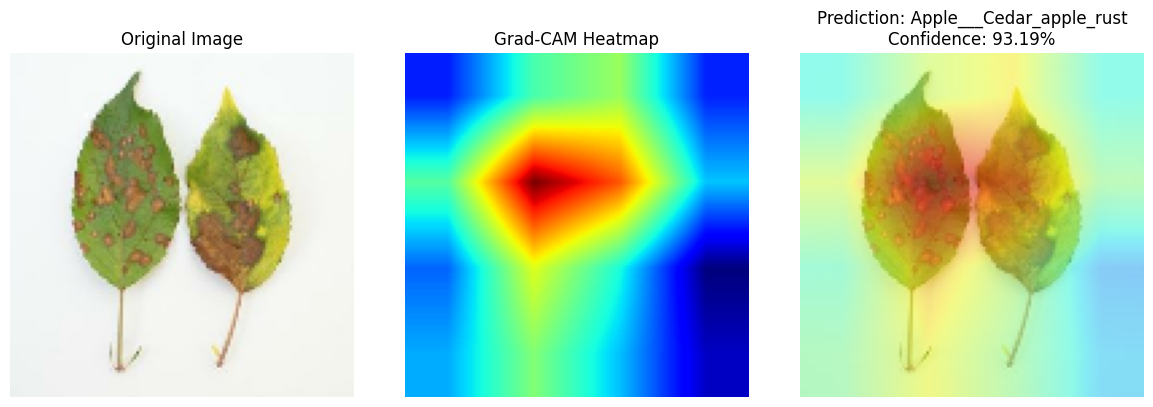

In [105]:

# 1. Find the nested MobileNetV3 backbone
backbone_idx = None
backbone = None

for i, layer in enumerate(finetuned_model.layers):
    if isinstance(layer, tf.keras.Model):
        backbone_idx = i
        backbone = layer
        break

if backbone is None:
    raise ValueError("Could not find the nested backbone model.")

print("Backbone:", backbone.name)

# 2. Find the final convolutional layer INSIDE the backbone
last_conv = find_last_conv(backbone)

if last_conv is None:
    raise ValueError("No convolutional layer found in backbone.")

print("Last convolutional layer:", last_conv.name)

# 3. Build a feature extractor using the backbone's own graph
feature_extractor = tf.keras.Model(
    inputs=backbone.inputs,
    outputs=[last_conv.output, backbone.output]
)

# 4. Grad-CAM function
def gradcam_for_path(path, class_index=None):

    image = decode_resize(
        tf.constant(path),
        tf.constant(0)
    )[0]

    x = image[None, ...]

    # Apply any layers before the backbone
    for layer in finetuned_model.layers[:backbone_idx]:
        if isinstance(layer, tf.keras.layers.InputLayer):
            continue
        x = layer(x)

    with tf.GradientTape() as tape:

        # Get convolutional features and backbone output
        conv_features, backbone_output = feature_extractor(
            x, training=False
        )

        # Pass backbone output through the classification head
        predictions = backbone_output

        for layer in finetuned_model.layers[backbone_idx + 1:]:
            predictions = layer(predictions, training=False)

        if class_index is None:
            class_index = tf.argmax(predictions[0])

        class_score = predictions[:, class_index]

    # Calculate gradients
    gradients = tape.gradient(class_score, conv_features)

    if gradients is None:
        raise RuntimeError("Gradients are None. Check the backbone/head connection.")

    # Global average pooling of gradients
    weights = tf.reduce_mean(gradients, axis=(1, 2))

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        conv_features * weights[:, None, None, :],
        axis=-1
    )[0]

    # Normalize heatmap
    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + 1e-8

    heatmap = tf.image.resize(
        heatmap[..., None],
        IMG_SIZE
    ).numpy().squeeze()

    original = image.numpy() / 255.0

    # Overlay
    heatmap_color = plt.get_cmap("jet")(heatmap)[..., :3]

    overlay = np.clip(
        0.55 * original + 0.45 * heatmap_color,
        0, 1
    )

    return original, heatmap, overlay, int(class_index), predictions.numpy()[0]


# 5. Select correct and incorrect predictions
indices = []

for correct in [True, False]:
    candidates = np.where((pred_test == y_test) == correct)[0][:3]
    indices.extend(candidates.tolist())


# 6. Generate Grad-CAM visualizations
for i in indices:

    path = plantdoc_test_mapped.iloc[i]["path"]

    orig, heat, overlay, pred_idx, probabilities = gradcam_for_path(
        path,
        int(pred_test[i])
    )

    confidence = probabilities[pred_idx]

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))

    ax[0].imshow(orig)
    ax[0].set_title("Original Image")

    ax[1].imshow(heat, cmap="jet")
    ax[1].set_title("Grad-CAM Heatmap")

    ax[2].imshow(overlay)
    ax[2].set_title(
        f"Prediction: {class_names[pred_idx]}\n"
        f"Confidence: {confidence:.2%}"
    )

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.show()


## 15. Confidence calibration and uncertainty

,model,temperature,ECE,NLL
0,before,1.00000,0.141675,1.944520
1,temperature_scaled,1.53409,0.051368,1.802353


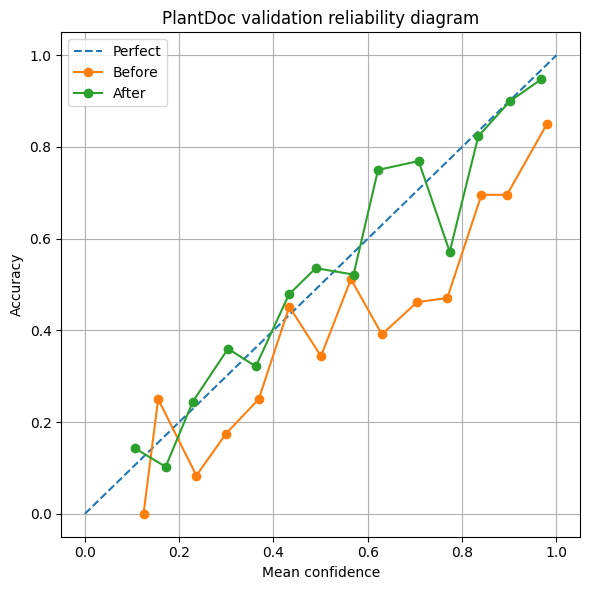

Temperature: 1.5340901973339145
Coverage at confidence threshold: 0.19498607242339833
Accuracy among accepted: 0.8142857142857143


In [103]:

from scipy.optimize import minimize
from sklearn.metrics import log_loss

pd_val_probs = predict_probs(finetuned_model, pd_val, tta=False)
y_cal = pd_val.label.to_numpy(dtype=np.int32)
logp = np.log(np.clip(pd_val_probs, 1e-8, 1.))

def temp_probs(t):
    z = logp / float(t)
    z -= z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

opt = minimize(lambda q: log_loss(y_cal, temp_probs(np.exp(q[0])),
                                  labels=np.arange(len(class_names))),
               x0=[0.], method="Nelder-Mead")
temperature = float(np.exp(opt.x[0]))
cal_probs = temp_probs(temperature)

def calc_ece(y, probs, bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    correct = (pred == y).astype(float)
    rows, ece = [], 0.
    edges = np.linspace(0, 1, bins+1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            acc, c = correct[mask].mean(), conf[mask].mean()
            ece += mask.mean() * abs(acc-c)
            rows.append({"lower": lo, "upper": hi, "count": int(mask.sum()),
                         "accuracy": acc, "confidence": c})
    return ece, pd.DataFrame(rows)

ece0, bins0 = calc_ece(y_cal, pd_val_probs)
ece1, bins1 = calc_ece(y_cal, cal_probs)
calibration_report = pd.DataFrame([
    {"model":"before", "temperature":1., "ECE":ece0,
     "NLL":log_loss(y_cal, pd_val_probs, labels=np.arange(len(class_names)))},
    {"model":"temperature_scaled", "temperature":temperature, "ECE":ece1,
     "NLL":log_loss(y_cal, cal_probs, labels=np.arange(len(class_names)))}
])
display(calibration_report)
calibration_report.to_csv(OUTPUT_DIR / "m3_calibration_report.csv", index=False)
bins1.to_csv(OUTPUT_DIR / "m3_reliability_bins.csv", index=False)

plt.figure(figsize=(6,6))
plt.plot([0,1],[0,1],"--",label="Perfect")
if len(bins0): plt.plot(bins0.confidence,bins0.accuracy,"o-",label="Before")
if len(bins1): plt.plot(bins1.confidence,bins1.accuracy,"o-",label="After")
plt.xlabel("Mean confidence"); plt.ylabel("Accuracy")
plt.title("PlantDoc validation reliability diagram"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"m3_reliability_diagram.png",dpi=180); plt.show()

CONFIDENCE_THRESHOLD = 0.70
accepted = cal_probs.max(1) >= CONFIDENCE_THRESHOLD
print("Temperature:", temperature)
print("Coverage at confidence threshold:", accepted.mean())
print("Accuracy among accepted:", accuracy_score(y_cal[accepted], cal_probs.argmax(1)[accepted])
      if accepted.any() else "No accepted predictions")
with open(OUTPUT_DIR/"m3_calibration_config.json","w") as f:
    json.dump({"temperature":temperature,"confidence_threshold":CONFIDENCE_THRESHOLD,
               "calibration_source":"PlantDoc validation"},f,indent=2)


## 16. Model optimization — TFLite, optional ONNX, and CPU latency

In [106]:

import platform
import time
import json
import numpy as np
import pandas as pd
import tensorflow as tf

# ==========================================
# 1. SAVE KERAS MODEL
# ==========================================

keras_out = OUTPUT_DIR / "mobilenetv3_plantdoc_final.keras"

finetuned_model.save(keras_out)

print("Keras model saved:", keras_out)


# ==========================================
# 2. CONVERT TO TFLITE FLOAT32
# ==========================================

t0 = time.perf_counter()

tflite_fp32 = OUTPUT_DIR / "mobilenetv3_plantdoc_float32.tflite"

converter = tf.lite.TFLiteConverter.from_keras_model(finetuned_model)
tflite_fp32.write_bytes(converter.convert())

fp32_conversion_time = time.perf_counter() - t0

print("Float32 TFLite exported.")


# ==========================================
# 3. DYNAMIC RANGE QUANTIZATION
# ==========================================

t0 = time.perf_counter()

tflite_dynamic = OUTPUT_DIR / "mobilenetv3_plantdoc_dynamic_quant.tflite"

converter = tf.lite.TFLiteConverter.from_keras_model(finetuned_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_dynamic.write_bytes(converter.convert())

dynamic_conversion_time = time.perf_counter() - t0

print("Dynamic quantization exported.")


# ==========================================
# 4. PREPARE TEST SAMPLE
# ==========================================

sample = decode_resize(
    tf.constant(plantdoc_test_mapped.iloc[0]["path"]),
    tf.constant(0)
)[0][None, ...]

# Keras CPU benchmark
with tf.device("/CPU:0"):

    for _ in range(5):
        _ = finetuned_model(sample, training=False)

    keras_latency = []

    for _ in range(30):
        t0 = time.perf_counter()
        _ = finetuned_model(sample, training=False)
        keras_latency.append((time.perf_counter() - t0) * 1000)


# ==========================================
# 5. TFLITE CPU BENCHMARK
# ==========================================

def benchmark_tflite(model_path, sample, repetitions=30):

    interpreter = tf.lite.Interpreter(
        model_path=str(model_path),
        num_threads=2
    )

    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    input_data = sample.astype(input_details[0]["dtype"])

    def run_inference():
        interpreter.set_tensor(input_details[0]["index"], input_data)
        interpreter.invoke()
        return interpreter.get_tensor(output_details[0]["index"])

    for _ in range(5):
        run_inference()

    timings = []

    for _ in range(repetitions):
        t0 = time.perf_counter()
        output = run_inference()
        timings.append((time.perf_counter() - t0) * 1000)

    return output[0], timings


fp32_prediction, fp32_latency = benchmark_tflite(tflite_fp32, sample.numpy())
dynamic_prediction, dynamic_latency = benchmark_tflite(tflite_dynamic, sample.numpy())


# ==========================================
# 6. CHECK QUANTIZATION ACCURACY
# ==========================================

# Compare predictions for the entire PlantDoc test cohort.
def evaluate_tflite(model_path, df):

    interpreter = tf.lite.Interpreter(
        model_path=str(model_path),
        num_threads=2
    )
    interpreter.allocate_tensors()

    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]

    predictions = []

    for start in range(0, len(df), BATCH_SIZE):

        batch_df = df.iloc[start:start+BATCH_SIZE]

        ds = tf.data.Dataset.from_tensor_slices(
            (
                batch_df["path"].astype(str).to_numpy(),
                batch_df["label"].astype(np.int32).to_numpy()
            )
        ).map(decode_resize, num_parallel_calls=AUTOTUNE)

        for images, _ in ds:

            image = images.numpy()[None, ...].astype(inp["dtype"])

            interpreter.set_tensor(inp["index"], image)
            interpreter.invoke()

            predictions.append(
                interpreter.get_tensor(out["index"])[0]
            )

    return np.asarray(predictions)


tflite_fp32_probs = evaluate_tflite(tflite_fp32, plantdoc_test_mapped)
tflite_dynamic_probs = evaluate_tflite(tflite_dynamic, plantdoc_test_mapped)

y_true = plantdoc_test_mapped["label"].to_numpy()

fp32_acc = np.mean(tflite_fp32_probs.argmax(1) == y_true)
dynamic_acc = np.mean(tflite_dynamic_probs.argmax(1) == y_true)

print("TFLite FP32 accuracy:", fp32_acc)
print("TFLite Dynamic accuracy:", dynamic_acc)


# ==========================================
# 7. MODEL SIZE AND LATENCY REPORT
# ==========================================

optimization_report = {

    "keras_size_mb": keras_out.stat().st_size / 1024**2,

    "tflite_fp32_size_mb": tflite_fp32.stat().st_size / 1024**2,

    "tflite_dynamic_size_mb": tflite_dynamic.stat().st_size / 1024**2,

    "keras_cpu_latency_mean_ms": float(np.mean(keras_latency)),

    "tflite_fp32_latency_mean_ms": float(np.mean(fp32_latency)),

    "tflite_dynamic_latency_mean_ms": float(np.mean(dynamic_latency)),

    "tflite_fp32_accuracy": float(fp32_acc),

    "tflite_dynamic_accuracy": float(dynamic_acc),

    "fp32_conversion_time_sec": fp32_conversion_time,

    "dynamic_conversion_time_sec": dynamic_conversion_time,

    "tensorflow": tf.__version__,

    "python": platform.python_version()
}

display(pd.DataFrame([optimization_report]))

with open(OUTPUT_DIR / "m3_optimization_report.json", "w") as f:
    json.dump(optimization_report, f, indent=2)


Keras model saved: /kaggle/working/AI_Crop_Doctor_M3_Finetuned/mobilenetv3_plantdoc_final.keras
INFO:tensorflow:Assets written to: /tmp/tmpiryozgof/assets


INFO:tensorflow:Assets written to: /tmp/tmpiryozgof/assets


Saved artifact at '/tmp/tmpiryozgof'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='input_layer_4')
Output Type:
  TensorSpec(shape=(None, 38), dtype=tf.float32, name=None)
Captures:
  137019735792848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735793232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735796304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735792464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735789968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735789008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735787472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735796496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735796688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735790352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735794

INFO:tensorflow:Assets written to: /tmp/tmpmj3o3g89/assets


Saved artifact at '/tmp/tmpmj3o3g89'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='input_layer_4')
Output Type:
  TensorSpec(shape=(None, 38), dtype=tf.float32, name=None)
Captures:
  137019735792848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735793232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735796304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735792464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735789968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735789008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735787472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735796496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735796688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735790352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137019735794

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite FP32 accuracy: 0.4444444444444444
TFLite Dynamic accuracy: 0.4444444444444444


,keras_size_mb,tflite_fp32_size_mb,tflite_dynamic_size_mb,keras_cpu_latency_mean_ms,tflite_fp32_latency_mean_ms,tflite_dynamic_latency_mean_ms,tflite_fp32_accuracy,tflite_dynamic_accuracy,fp32_conversion_time_sec,dynamic_conversion_time_sec,tensorflow,python
0,12.215032,11.510609,3.191048,234.58528,1.670553,3.75576,0.444444,0.444444,9.527015,9.794532,2.21.0,3.13.16
